In [2]:
import pandas as pd

df = pd.read_csv("../data/input.csv")
df

,item,quantity
0,A,999
1,B,20
2,C,30


In [3]:
df.shape

(3, 2)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   item      3 non-null      str  
 1   quantity  3 non-null      int64
dtypes: int64(1), str(1)
memory usage: 180.0 bytes


In [5]:
df.describe()

,quantity
count,3.000000
mean,349.666667
std,562.361390
min,20.000000
25%,25.000000
50%,30.000000
75%,514.500000
max,999.000000


In [6]:
df.isna().sum()

item        0
quantity    0
dtype: int64

In [7]:
df["monthly_demand"] = [1000, 10, 15]

df["inventory_months"] = (
    df["quantity"] / df["monthly_demand"]
)

df

,item,quantity,monthly_demand,inventory_months
0,A,999,1000,0.999
1,B,20,10,2.000
2,C,30,15,2.000


In [8]:
import pandas as pd
from itertools import product

skus = [f"A{i:03d}" for i in range(1, 11)]
months = pd.date_range("2026-01-01", periods=12, freq="MS")

df_monthly = pd.DataFrame(
    product(skus, months),
    columns=["sku", "month"]
)

print(df_monthly.shape)
display(df_monthly.head())

(120, 2)


,sku,month
0,A001,2026-01-01
1,A001,2026-02-01
2,A001,2026-03-01
3,A001,2026-04-01
4,A001,2026-05-01


In [9]:
import numpy as np

rng = np.random.default_rng(42)

# SKUごとに異なる基本需要を設定
base_demand = {
    sku: 100 + i * 50
    for i, sku in enumerate(skus)
}

# 基本需要に月次変動を加える
df_monthly["demand"] = [
    max(0, round(base_demand[sku] * rng.normal(1.0, 0.15)))
    for sku in df_monthly["sku"]
]

display(df_monthly.head(15))

,sku,month,demand
0,A001,2026-01-01,105
1,A001,2026-02-01,84
2,A001,2026-03-01,111
3,A001,2026-04-01,114
4,A001,2026-05-01,71
5,A001,2026-06-01,80
6,A001,2026-07-01,102
7,A001,2026-08-01,95
8,A001,2026-09-01,100
9,A001,2026-10-01,87


In [10]:
skus_sample = ["A001", "A002", "A003"]

base_demand_sample = {}

for i, sku in enumerate(skus_sample):
    base_demand_sample[sku] = 100 + i * 50
    print(i, sku, base_demand_sample[sku])

print(base_demand_sample)

0 A001 100
1 A002 150
2 A003 200
{'A001': 100, 'A002': 150, 'A003': 200}


In [11]:
base_demand_sample["A002"] = 999

print(base_demand_sample)

{'A001': 100, 'A002': 999, 'A003': 200}


In [12]:
rng = np.random.default_rng(42)

demands = []

for sku in df_monthly["sku"]:
    base = base_demand[sku]
    variation = rng.normal(1.0, 0.15)
    demand = max(0, round(base * variation))

    demands.append(demand)

df_monthly["demand"] = demands

In [13]:
df_monthly["base_demand"] = df_monthly["sku"].map(base_demand)

display(df_monthly.head())

,sku,month,demand,base_demand
0,A001,2026-01-01,105,100
1,A001,2026-02-01,84,100
2,A001,2026-03-01,111,100
3,A001,2026-04-01,114,100
4,A001,2026-05-01,71,100


In [14]:
print(df_monthly[["sku", "demand", "base_demand"]].head(15))

     sku  demand  base_demand
0   A001     105          100
1   A001      84          100
2   A001     111          100
3   A001     114          100
4   A001      71          100
5   A001      80          100
6   A001     102          100
7   A001      95          100
8   A001     100          100
9   A001      87          100
10  A001     113          100
11  A001     112          100
12  A002     151          150
13  A002     175          150
14  A002     161          150


In [15]:
df_test = pd.DataFrame({
    "sku": ["A001", "A002", "A999"]
})

df_test["base_demand"] = df_test["sku"].map(base_demand)

display(df_test)

,sku,base_demand
0,A001,100.0
1,A002,150.0
2,A999,NaN


In [16]:
# 欠損値があるかを行ごとに判定
missing = df_test["base_demand"].isna()

print(missing)

# 欠損している行だけを取り出す
df_missing = df_test.loc[missing]

display(df_missing)

0    False
1    False
2     True
Name: base_demand, dtype: bool


,sku,base_demand
2,A999,NaN


In [17]:
condition = (
    (df_monthly["sku"] == "A001")
    & (df_monthly["demand"] < 100)
)

df_selected = df_monthly.loc[condition]

display(df_selected)

,sku,month,demand,base_demand
1,A001,2026-02-01,84,100
4,A001,2026-05-01,71,100
5,A001,2026-06-01,80,100
7,A001,2026-08-01,95,100
9,A001,2026-10-01,87,100


In [18]:
demand_summary = (
    df_monthly
    .groupby("sku")["demand"]
    .agg(["count", "mean", "std", "min", "max"])
)

display(demand_summary)

,count,mean,std,min,max
sku,,,,,
A001,12,97.833333,14.440054,71,114
A002,12,152.416667,16.571928,128,178
A003,12,207.750000,24.827130,176,264
A004,12,253.500000,22.468159,218,283
A005,12,300.416667,37.953221,234,367
A006,12,340.000000,44.759966,262,395
A007,12,397.500000,32.382655,345,441
A008,12,431.250000,53.868738,336,495
A009,12,475.333333,59.073657,401,597


In [19]:
df_monthly["demand"].describe()

count    120.000000
mean     319.841667
std      143.399600
min       71.000000
25%      211.750000
50%      327.000000
75%      429.250000
max      682.000000
Name: demand, dtype: float64

In [20]:
df_monthly.groupby("sku")["demand"].describe()

,count,mean,std,min,25%,50%,75%,max
sku,,,,,,,,
A001,12.0,97.833333,14.440054,71.0,86.25,101.0,111.25,114.0
A002,12.0,152.416667,16.571928,128.0,143.25,150.0,163.25,178.0
A003,12.0,207.750000,24.827130,176.0,187.75,211.5,216.50,264.0
A004,12.0,253.500000,22.468159,218.0,240.75,258.0,271.00,283.0
A005,12.0,300.416667,37.953221,234.0,277.00,295.5,328.75,367.0
A006,12.0,340.000000,44.759966,262.0,317.25,336.0,382.50,395.0
A007,12.0,397.500000,32.382655,345.0,376.25,395.0,427.75,441.0
A008,12.0,431.250000,53.868738,336.0,405.75,444.0,480.50,495.0
A009,12.0,475.333333,59.073657,401.0,429.75,472.5,496.25,597.0


In [21]:
demand_summary["cv"] = (
    demand_summary["std"] / demand_summary["mean"]
)

display(demand_summary[["mean", "std", "cv"]])

,mean,std,cv
sku,,,
A001,97.833333,14.440054,0.147599
A002,152.416667,16.571928,0.108728
A003,207.750000,24.827130,0.119505
A004,253.500000,22.468159,0.088632
A005,300.416667,37.953221,0.126335
A006,340.000000,44.759966,0.131647
A007,397.500000,32.382655,0.081466
A008,431.250000,53.868738,0.124913
A009,475.333333,59.073657,0.124278


In [22]:
df_forecast = pd.DataFrame({
    "actual": [100, 150, 80, 170],
    "forecast": [100, 145, 85, 165]
})

df_forecast["error"] = (
    df_forecast["actual"] - df_forecast["forecast"]
)

display(df_forecast)

print("販売実績の標準偏差:", df_forecast["actual"].std())
print("予測誤差の標準偏差:", df_forecast["error"].std())
print("平均予測誤差:", df_forecast["error"].mean())

,actual,forecast,error
0,100,100,0
1,150,145,5
2,80,85,-5
3,170,165,5


販売実績の標準偏差: 42.03173404306164
予測誤差の標準偏差: 4.7871355387816905
平均予測誤差: 1.25


In [23]:
df_versions = pd.DataFrame({
    "forecast_month": ["2026-03", "2026-06", "2026-08"],
    "target_month": ["2026-09"] * 3,
    "forecast": [150, 105, 125],
    "actual": [120] * 3
})

df_versions["error"] = (
    df_versions["actual"] - df_versions["forecast"]
)

df_versions["absolute_error"] = df_versions["error"].abs()

display(df_versions)
print("平均誤差:", df_versions["error"].mean())
print("平均絶対誤差:", df_versions["absolute_error"].mean())

,forecast_month,target_month,forecast,actual,error,absolute_error
0,2026-03,2026-09,150,120,-30,30
1,2026-06,2026-09,105,120,15,15
2,2026-08,2026-09,125,120,-5,5


平均誤差: -6.666666666666667
平均絶対誤差: 16.666666666666668


In [24]:
df_push = pd.DataFrame({
    "month": pd.date_range("2026-01-01", periods=9, freq="MS"),
    "consumption": [100] * 9,
    "shipment": [100, 100, 100, 300, 0, 0, 100, 100, 100]
})

# 期首の卸在庫を100と仮定
initial_inventory = 100

df_push["wholesale_inventory"] = (
    initial_inventory
    + (df_push["shipment"] - df_push["consumption"]).cumsum()
)

display(df_push)

,month,consumption,shipment,wholesale_inventory
0,2026-01-01,100,100,100
1,2026-02-01,100,100,100
2,2026-03-01,100,100,100
3,2026-04-01,100,300,300
4,2026-05-01,100,0,200
5,2026-06-01,100,0,100
6,2026-07-01,100,100,100
7,2026-08-01,100,100,100
8,2026-09-01,100,100,100


In [25]:
df_push["shipment_ma3"] = (
    df_push["shipment"].rolling(window=3).mean()
)

df_push["consumption_ma3"] = (
    df_push["consumption"].rolling(window=3).mean()
)

display(df_push)

,month,consumption,shipment,wholesale_inventory,shipment_ma3,consumption_ma3
0,2026-01-01,100,100,100,NaN,NaN
1,2026-02-01,100,100,100,NaN,NaN
2,2026-03-01,100,100,100,100.000000,100.0
3,2026-04-01,100,300,300,166.666667,100.0
4,2026-05-01,100,0,200,133.333333,100.0
5,2026-06-01,100,0,100,100.000000,100.0
6,2026-07-01,100,100,100,33.333333,100.0
7,2026-08-01,100,100,100,66.666667,100.0
8,2026-09-01,100,100,100,100.000000,100.0


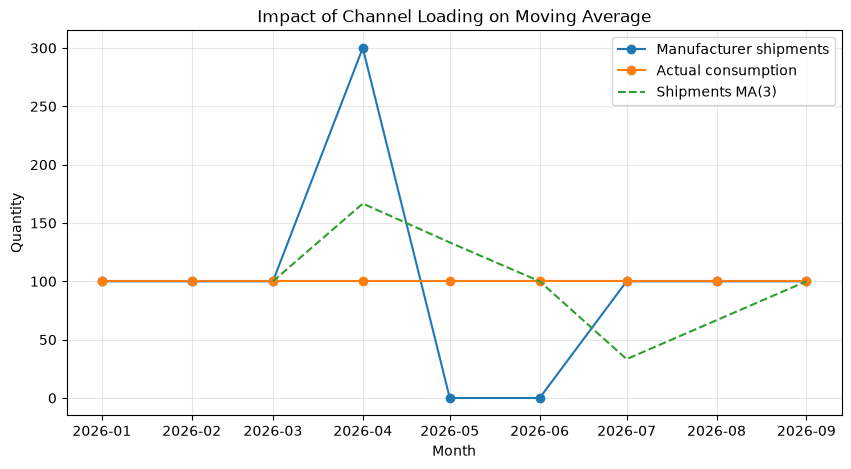

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    df_push["month"],
    df_push["shipment"],
    marker="o",
    label="Manufacturer shipments"
)

ax.plot(
    df_push["month"],
    df_push["consumption"],
    marker="o",
    label="Actual consumption"
)

ax.plot(
    df_push["month"],
    df_push["shipment_ma3"],
    linestyle="--",
    label="Shipments MA(3)"
)

ax.set_title("Impact of Channel Loading on Moving Average")
ax.set_xlabel("Month")
ax.set_ylabel("Quantity")
ax.legend()
ax.grid(alpha=0.3)

plt.show()